# Energia: auditoria exploratória de baixa prioridade

O nome `energy` e a identificação ACS712 não bastam para declarar kWh, W ou A.
A documentação do fabricante identifica ACS712 como sensor de corrente; não foi localizada
uma especificação da transformação feita pelo firmware para o campo do banco.
Os valores são mantidos na escala registrada, com unidade não confirmada.
Não se calcula consumo, integral, economia ou estado ligado/desligado por limiar arbitrário.
A comparação com temperatura é apenas uma sobreposição temporal descritiva.

**Estado:** análise executada com extrações reais em 31/10/2026. As consultas,
os CSVs e seus hashes estão preservados em `data/raw/questdb/complementares/`.
Mantenha `ATUALIZAR = False` para reproduzir essa extração sem nova consulta.
As saídas e as limitações de interpretação estão registradas ao final do notebook.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "code/sensores.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Execute dentro do projeto.")
BASE = ROOT / "code/tcc"
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
from apoio_consultas import consultar_cache

INICIO = pd.Timestamp("2026-06-10T00:00:00Z")
FIM = pd.Timestamp("2026-07-26T00:00:00Z")
GRADE = pd.date_range(INICIO, FIM, freq="5min", inclusive="left", name="timestamp")
RAW = BASE / "data/raw/questdb/complementares"
ATUALIZAR = False
OUT = BASE / "results/energia"
TABLES, FIGS = OUT / "tabelas", OUT / "figuras"
for p in [OUT, TABLES, FIGS]:
    p.mkdir(parents=True, exist_ok=True)


In [2]:
sql_inventario = "SELECT sensor_id, sensor_model, count(*) AS total, min(measured_in) AS inicio, max(measured_in) AS fim, min(energy) AS minimo, max(energy) AS maximo FROM sensor_energy WHERE environment = '1006' AND measured_in >= '2026-06-10T00:00:00Z' AND measured_in < '2026-07-26T00:00:00Z' GROUP BY sensor_id, sensor_model ORDER BY sensor_id"
inventario = consultar_cache(sql_inventario, RAW / "inventario_energia.csv", ATUALIZAR)
inventario = inventario.rename(columns={"total": "registros", "inicio": "primeiro", "fim": "ultimo"})
inventario.to_csv(TABLES / "inventario_energia.csv", index=False)
display(inventario)
if inventario.empty:
    raise RuntimeError("Não há energia no período selecionado; não gerar gráfico sem dados.")


,sensor_id,sensor_model,registros,primeiro,ultimo,minimo,maximo
0,23,ACS712,8193,2026-06-10T01:43:35.578000Z,2026-06-11T22:31:36.004000Z,0.0,9.13


In [3]:
sql = """SELECT measured_in, sensor_id, avg(energy) AS valor_medio,
 min(energy) AS minimo, max(energy) AS maximo, count(*) AS quantidade,
 count(energy) AS quantidade_validos FROM sensor_energy WHERE environment = '1006'
 AND measured_in >= '2026-06-10T00:00:00Z' AND measured_in < '2026-07-26T00:00:00Z'
 SAMPLE BY 5m ORDER BY measured_in, sensor_id"""
ARQUIVO_ENERGIA = RAW / "energia_1006_5min.csv"
e = consultar_cache(sql, ARQUIVO_ENERGIA, ATUALIZAR)
e.measured_in = pd.to_datetime(e.measured_in, utc=True, errors="raise")
e.sensor_id = pd.to_numeric(e.sensor_id, errors="raise").astype(int)
for c in ["valor_medio", "minimo", "maximo", "quantidade", "quantidade_validos"]:
    e[c] = pd.to_numeric(e[c], errors="raise")
assert not e.duplicated(["measured_in", "sensor_id"]).any()
assert e.measured_in.between(INICIO, FIM, inclusive="left").all()
assert e.measured_in.eq(e.measured_in.dt.floor("5min")).all()
assert np.isfinite(e.valor_medio.dropna().to_numpy()).all()
energia = e.pivot(index="measured_in", columns="sensor_id", values="valor_medio").reindex(GRADE)
if energia.dropna(how="all").empty:
    raise RuntimeError("Não há janelas de energia numericamente válidas.")
energia.to_csv(BASE / "data/processed/energia_1006_5min.csv", index_label="timestamp")
cadastro = pd.DataFrame(json.loads((ROOT / "code/sensores.json").read_text())).set_index("id")
resumo_e = pd.DataFrame({"sensor_id": energia.columns,
                        "janelas_validas": energia.notna().sum().to_numpy(),
                        "cobertura_pct": 100 * energia.notna().mean().to_numpy(),
                        "media_registrada": energia.mean().to_numpy(),
                        "min_registrado": energia.min().to_numpy(),
                        "max_registrado": energia.max().to_numpy()})
resumo_e["nome_cadastro"] = resumo_e.sensor_id.map(cadastro.name)
resumo_e.to_csv(TABLES / "resumo_energia.csv", index=False)
display(resumo_e)


,sensor_id,janelas_validas,cobertura_pct,media_registrada,min_registrado,max_registrado,nome_cadastro
0,23,539,4.068539,0.382639,0.0,6.865,Ar Samsung Direita Vilalba


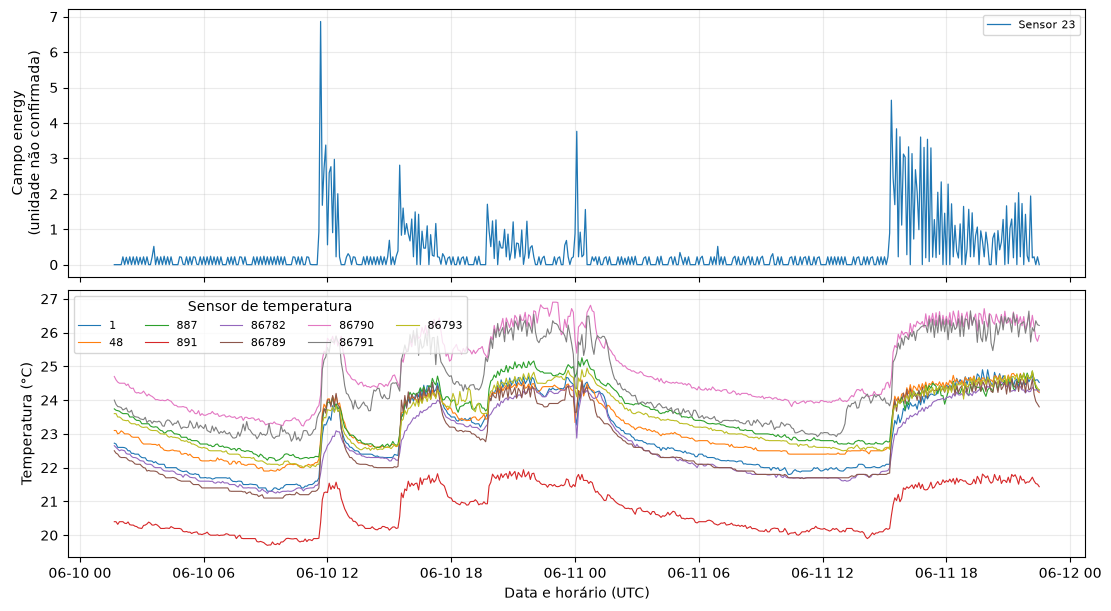

Auditoria exploratória concluída: /home/gustavomoura/Documents/temperatureMonitoring/code/tcc/results/energia


In [4]:
# Usar a matriz completa de temperatura para mostrar somente a interseção disponível.
temp = pd.read_csv(BASE / "data/processed/temperaturas_1006_5min.csv", index_col="timestamp")
temp.index = pd.to_datetime(temp.index, utc=True)
a = energia.dropna(how="all").index.min()
b = energia.dropna(how="all").index.max()
comparacao = energia.loc[a:b].add_prefix("energy_").join(temp.loc[a:b].add_prefix("T_"))
comparacao.to_csv(OUT / "sobreposicao_temporal.csv", index_label="timestamp")
fig, eixos = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout="constrained")
for sid in energia.columns:
    eixos[0].plot(energia.loc[a:b, sid], lw=0.9, label=f"Sensor {sid}")
eixos[0].set_ylabel("Campo energy\n(unidade não confirmada)")
eixos[0].legend(fontsize=8)
for sid in temp.columns:
    eixos[1].plot(temp.loc[a:b, sid], lw=0.8, label=sid)
eixos[1].set(ylabel="Temperatura (°C)", xlabel="Data e horário (UTC)")
eixos[1].legend(title="Sensor de temperatura", ncol=5, fontsize=8)
for ax in eixos:
    ax.grid(alpha=0.25)
for ext in ["png", "pdf"]:
    fig.savefig(FIGS / f"energia_temperatura_exploratoria.{ext}", dpi=240, bbox_inches="tight")
plt.show()
config = {"executado_em_utc": pd.Timestamp.now(tz="UTC").isoformat(),
          "sha256_extracao": hashlib.sha256(ARQUIVO_ENERGIA.read_bytes()).hexdigest(),
          "unidade_energy": "não confirmada", "conversao_para_consumo": False,
          "limiar_ligado_desligado": None,
          "primeira_janela": a.isoformat(), "ultima_janela": b.isoformat(),
          "sensor_ids": [int(x) for x in energia.columns],
          "semantica": "escala original do banco; ACS712 é sensor de corrente, transformação no firmware não confirmada",
          "fonte_fabricante": "https://www.allegromicro.com/en/products/sense/current-sensor-ics/integrated-current-sensors/acs712"}
(OUT / "configuracao_energia.json").write_text(json.dumps(config, ensure_ascii=False, indent=2))
print("Auditoria exploratória concluída:", OUT)
